[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch49_LabCh49_Tiny_CLIP.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 49: CLIP and Multimodal Models** (Part X: Seeing More).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=49](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=49)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch49 - A tiny CLIP
## Train a picture encoder and a caption encoder together, then classify, search and probe with sentences

This lab goes with **Chapter 49** of *The Why Book of Deep Learning, Part 2*.

CLIP (2021) trains two networks at once: one reads an image, one reads its caption, and the loss asks both to
put a matching pair at the same point of one shared space. After that a sentence can do the work of a
classifier or of a search query. Here you build the whole thing at a size that trains in a minute: coloured
MNIST digits as the images, short captions made from templates as the text, and the contrastive loss of
Chapter 48 with one change, a temperature that is learnt.

| The miniature | value |
|---|---|
| images | 60,000 MNIST digits, each tinted one of 6 colours: 28 × 28 × 3 |
| captions | 13 wordings: "a photo of a red three", "the number 3 written in red ink", "a 3", "something red" ... |
| image tower | the Chapter 48 encoder (three stride-2 convolutions) and a linear projection to 64 numbers |
| text tower | word table, position table, one transformer block, mean over the words, linear projection to 64 |
| loss | `info_nce` from Chapter 48, unchanged, with a **learnt** temperature starting at 0.07 |
| training | 1,500 steps of 256 pairs (6.4 passes), with 10 of the 60 colour-digit combinations never shown |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Build captions and a tokenizer, and count both towers by hand | Steps 2 to 5 |
| Use the contrastive loss with a learnt temperature and say what the temperature does | Steps 6 to 9 |
| Classify with sentences and no classifier head (zero-shot classification) | Step 10 |
| Compare prompt templates and average them | Step 11 |
| Explain why a similarity score is not a probability | Step 12 |
| Search images with a sentence | Step 13 |
| Test what the text tower knows: synonyms it was never told, and word order it never learnt | Step 14 |
| Tell apart three kinds of "new": a new combination, a new kind of object, and a new word | Steps 15 to 17 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about two minutes on a laptop CPU. Most of it is Step 8 (the main training run) and Step 17
> (a second, shorter run). No GPU is needed. The only downloads are MNIST and Fashion-MNIST from
> `keras.datasets`.

> **Honest scale:** this is a miniature. Its two towers have 142,016 parameters and its captions use a
> vocabulary of 39 words. CLIP was trained on about 400 million image-caption pairs from the web, with towers
> of tens to hundreds of millions of parameters. The numbers printed here describe this toy. They say nothing
> about what CLIP scores on anything. What carries over is the mechanism, and the kinds of success and failure.

---
## Step 1 - Imports and one seed

In [1]:
import os, time, math
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 49
keras.utils.set_random_seed(SEED)
np.set_printoptions(precision=2, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.21.0 | Keras 3.14.1


---
## Step 2 - The images: digits with a colour

Plain MNIST has one thing to say about each image: which digit it is. To make captions worth writing, every
digit gets a second property, an ink colour, drawn at random from six. The tint is not exact: each image gets
its own brightness and a small random shift in each colour channel, so "red" is a family of reds.

That gives 10 digits × 6 colours = **60 combinations**. Ten of them are **held out**: digit `d` in colour
number `d mod 6` (a red zero, a green one, a blue two, ...) never appears in training, in pictures or in
captions. Every digit is still seen in five colours, and every colour on eight or nine digits. Step 15 asks
whether the model can recognise the combinations it never met.

**Predict:** roughly how many of the 60,000 training images fall in the 10 held-out combinations?

X_train (60000, 28, 28, 3) | X_test (10000, 28, 28, 3)
held-out combinations: red zero, green one, blue two, yellow three, pink four, white five, red six, green seven, blue eight, yellow nine
training images in them: 10,012 of 60,000 (16.7%); left for training: 49,988
test images in them: 1,643 of 10,000


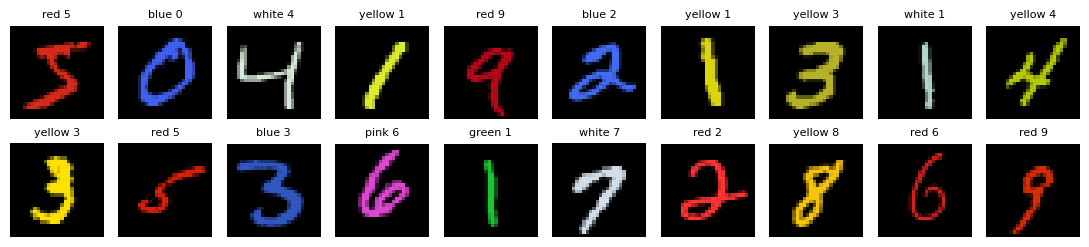

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = (x_train / 255.0).astype("float32")
x_test = (x_test / 255.0).astype("float32")

COLOURS = ["red", "green", "blue", "yellow", "pink", "white"]
RGB = np.array([[1.0, 0.15, 0.15], [0.15, 0.9, 0.15], [0.2, 0.35, 1.0],
                [1.0, 0.9, 0.1], [1.0, 0.3, 0.8], [1.0, 1.0, 1.0]], dtype="float32")
WORDS = ["zero", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]

def colourise(x, c, rng):
    """Tint grey images x (n, 28, 28) with colour numbers c (n,). Returns (n, 28, 28, 3), values 0 to 1."""
    tint = RGB[c] * rng.uniform(0.7, 1.0, (len(x), 1)) + rng.uniform(-0.1, 0.1, (len(x), 3))
    return np.clip(x[..., None] * tint[:, None, None, :], 0.0, 1.0).astype("float32")

rng = np.random.default_rng(SEED)
c_train = rng.integers(0, 6, len(x_train))
c_test = rng.integers(0, 6, len(x_test))
X_train, X_test = colourise(x_train, c_train, rng), colourise(x_test, c_test, rng)
held_train = c_train == (y_train % 6)          # the 10 combinations kept out of training
held_test = c_test == (y_test % 6)
print("X_train", X_train.shape, "| X_test", X_test.shape)
print("held-out combinations:", ", ".join(f"{COLOURS[d % 6]} {WORDS[d]}" for d in range(10)))
print(f"training images in them: {held_train.sum():,} of {len(x_train):,} "
      f"({100 * held_train.mean():.1f}%); left for training: {(~held_train).sum():,}")
print(f"test images in them: {held_test.sum():,} of {len(x_test):,}")

fig, ax = plt.subplots(2, 10, figsize=(11, 2.6))
for k in range(20):
    ax[k // 10, k % 10].imshow(X_train[k]); ax[k // 10, k % 10].axis("off")
    ax[k // 10, k % 10].set_title(f"{COLOURS[c_train[k]]} {y_train[k]}", fontsize=8)
plt.tight_layout(); plt.show()

---
## Step 3 - The captions and the tokenizer

CLIP's captions were whatever people had written next to pictures on the web: varied, partial and noisy. We
imitate two of those properties.

* **Varied wording.** Six templates that name colour and digit, four that name only the digit, three that
  name only the colour. The digit is written as a word or as a numeral, half the time each ("three" or "3").
* **Partial.** 60% of captions name both properties, 20% only the digit, 20% only the colour. A real caption
  never lists everything in the picture.

A fresh caption is drawn for an image every time it is used, so the model sees many captions per image.

The tokenizer is a word-level lookup (Chapter 33 has the grown-up kind): split on spaces, look each word up,
pad with 0 to 8 tokens.

**Predict:** nothing ever tells the model that "three" and "3" mean the same thing. Each caption uses one or
the other. Will their vectors end up close? Keep your answer for Step 14.

In [3]:
FULL = ["a photo of a {c} {d}", "a {c} {d}", "the digit {d} in {c}",
        "the number {d} written in {c} ink", "{c} handwritten {d}", "a drawing of a {c} {d}"]
DIGIT_ONLY = ["a photo of the digit {d}", "a {d}", "the number {d}", "a handwritten {d}"]
COLOUR_ONLY = ["something {c}", "a {c} drawing", "written in {c} ink"]

filler = sorted(set(" ".join(FULL + DIGIT_ONLY + COLOUR_ONLY).replace("{c}", "").replace("{d}", "").split()))
VOCAB = ["<pad>"] + filler + COLOURS + WORDS + [str(d) for d in range(10)]
TOKEN = {w: i for i, w in enumerate(VOCAB)}
V, L = len(VOCAB), 8                            # vocabulary size, caption length in tokens

def tokenize(sentence):
    ids = [TOKEN[w] for w in sentence.split()]
    assert len(ids) <= L, sentence
    return ids + [0] * (L - len(ids))

def caption(d, c, rng):
    """One random caption for digit d in colour number c."""
    r = rng.random()
    templates = FULL if r < 0.6 else DIGIT_ONLY if r < 0.8 else COLOUR_ONLY
    name = WORDS[d] if rng.random() < 0.5 else str(d)
    return templates[rng.integers(len(templates))].format(c=COLOURS[c], d=name)

print("vocabulary:", V, "words:", " ".join(VOCAB))
demo = np.random.default_rng(0)
for k in range(6):
    s = caption(y_train[k], c_train[k], demo)
    print(f"image {k} ({COLOURS[c_train[k]]} {y_train[k]}): {s!r:42} -> {tokenize(s)}")

vocabulary: 39 words: <pad> a digit drawing handwritten in ink number of photo something the written red green blue yellow pink white zero one two three four five six seven eight nine 0 1 2 3 4 5 6 7 8 9
image 0 (red 5): 'a five'                                   -> [1, 24, 0, 0, 0, 0, 0, 0]
image 1 (blue 0): 'a photo of a blue 0'                      -> [1, 9, 8, 1, 15, 29, 0, 0]
image 2 (white 4): 'written in white ink'                     -> [12, 5, 18, 6, 0, 0, 0, 0]
image 3 (yellow 1): 'yellow handwritten 1'                     -> [16, 4, 30, 0, 0, 0, 0, 0]
image 4 (red 9): 'a red drawing'                            -> [1, 13, 3, 0, 0, 0, 0, 0]
image 5 (blue 2): 'a drawing of a blue 2'                    -> [1, 3, 8, 1, 15, 31, 0, 0]


---
## Step 4 - The image tower

The image tower is the encoder of Chapter 48 (three stride-2 convolutions and a global average), with three
input channels instead of one, followed by one linear layer without a bias that maps its 128 features into
the shared space of **64 numbers**. CLIP ends its towers with the same kind of bias-free linear projection.

Count before Keras does. A convolution has `k·k·in·out + out` parameters (Chapter 14).

**Predict:** Chapter 48's encoder had 92,672 parameters with grey images. How many more does the first
convolution need for three colour channels?

In [4]:
D = 64                                           # width of the shared space

def make_image_tower():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 3)),
        layers.Conv2D(32, 3, strides=2, padding="same", activation="relu"),    # 28 -> 14
        layers.Conv2D(64, 3, strides=2, padding="same", activation="relu"),    # 14 -> 7
        layers.Conv2D(128, 3, strides=2, padding="same", activation="relu"),   # 7 -> 4
        layers.GlobalAveragePooling2D(),                                       # (4, 4, 128) -> (128,)
        layers.Dense(D, use_bias=False),                                       # into the shared space
    ], name="image_tower")

image_tower = make_image_tower()
conv1, conv2, conv3 = 3 * 3 * 3 * 32 + 32, 3 * 3 * 32 * 64 + 64, 3 * 3 * 64 * 128 + 128
proj_i = 128 * D
print("image tower by hand:", conv1, "+", conv2, "+", conv3, "+", proj_i, "=", conv1 + conv2 + conv3 + proj_i)
print("extra parameters for colour in the first convolution:", conv1 - (3 * 3 * 1 * 32 + 32))
assert image_tower.count_params() == conv1 + conv2 + conv3 + proj_i == 101440
print("a batch of images", X_train[:4].shape, "->", image_tower(X_train[:4]).shape)

image tower by hand: 896 + 18496 + 73856 + 8192 = 101440
extra parameters for colour in the first convolution: 576


a batch of images (4, 28, 28, 3) -> (4, 64)


---
## Step 5 - The text tower

The text tower is a very small transformer encoder (Chapters 22 and 23), the same kind of network CLIP uses
for text, shrunk:

1. a word table, `V × 64`, and a learnt position table, `8 × 64` (Chapter 34);
2. one pre-norm block: self-attention with 4 heads, then a feed-forward layer of width 128;
3. the **mean over the real words** (padding is masked out), which turns 8 vectors into one;
4. a bias-free linear projection into the shared space.

Parameter formulas from Chapter 35: attention `4d² + 4d`, feed-forward `d·f + f + f·d + d`, each LayerNorm `2d`.

**Predict:** with `d = 64` and `f = 128`, which part is largest: the word table, the attention or the
feed-forward layer?

In [5]:
class Positions(layers.Layer):
    """Adds a learnt vector for each position."""
    def build(self, shape):
        self.table = self.add_weight(shape=(shape[1], shape[2]), name="positions",
                                     initializer=keras.initializers.RandomNormal(stddev=0.02))
    def call(self, x):
        return x + self.table

class PadMask(layers.Layer):
    """(batch, L) token ids -> (batch, L, L) mask: every word may look at every real word, never at padding."""
    def call(self, ids):
        real = ids > 0
        return tf.logical_and(real[:, None, :], tf.ones_like(real)[:, :, None])

class MaskedMean(layers.Layer):
    """The mean of the word vectors, counting real words only."""
    def call(self, x, ids):
        real = tf.cast(ids > 0, x.dtype)[..., None]
        return tf.reduce_sum(x * real, axis=1) / tf.reduce_sum(real, axis=1)

def make_text_tower():
    ids = layers.Input(shape=(L,), dtype="int32")
    x = Positions()(layers.Embedding(V, D)(ids))                               # (L, 64)
    h = layers.LayerNormalization()(x)
    x = x + layers.MultiHeadAttention(num_heads=4, key_dim=D // 4)(h, h, attention_mask=PadMask()(ids))
    h = layers.LayerNormalization()(x)
    x = x + layers.Dense(D)(layers.Dense(128, activation="relu")(h))
    pooled = MaskedMean()(x, ids)                                              # (64,)
    return keras.Model(ids, layers.Dense(D, use_bias=False)(pooled), name="text_tower")

text_tower = make_text_tower()
words, positions = V * D, L * D
attention, feed_forward, norms = 4 * D * D + 4 * D, D * 128 + 128 + 128 * D + D, 2 * 2 * D
proj_t = D * D
parts = [words, positions, attention, norms, feed_forward, proj_t]
print("text tower by hand: words", words, "+ positions", positions, "+ attention", attention,
      "+ two LayerNorms", norms, "+ feed-forward", feed_forward, "+ projection", proj_t, "=", sum(parts))
assert text_tower.count_params() == sum(parts) == 40576
ids = np.array([tokenize("a photo of a red three"), tokenize("a 3")], dtype="int32")
print("token ids", ids.shape, "->", text_tower(ids).shape)
print("both towers:", image_tower.count_params() + text_tower.count_params(), "parameters, plus 1 for the temperature")

text tower by hand: words 2496 + positions 512 + attention 16640 + two LayerNorms 256 + feed-forward 16576 + projection 4096 = 40576


token ids (2, 8) -> (2, 64)
both towers: 142016 parameters, plus 1 for the temperature


### Why we see this

An image goes in as `(28, 28, 3)` and comes out as 64 numbers. A caption goes in as 8 integers and comes out as
64 numbers. The two towers share nothing except the width of their last layer. That one agreement is what
lets a picture be compared with a sentence.

The towers are lopsided, 101,440 against 40,576, and in the text tower the word table is the smallest part,
because the vocabulary is 39 words. In a real model the word table has tens of thousands of rows.

---
## Step 6 - The loss: Chapter 48's function, and a temperature that is learnt

The loss is `info_nce` from Chapter 48, copied without changing a character. There, row i was "view a of
image i" and column j was "view b of image j". Here row i is **image i** and column j is **caption j**. The
diagonal is still the right answer: each image must pick its own caption out of the batch (the rows), and
each caption its own image (the columns).

One thing changes. Chapter 48 fixed the temperature at 0.2 by hand. CLIP makes it a **parameter** and lets
gradient descent choose. To keep it positive, the parameter stored is `log_scale = ln(1 / temperature)`. It
starts at `ln(1 / 0.07)` and is capped at `ln(100)`, so the similarities are never multiplied by more than
100. Both numbers are CLIP's.

**Predict:** the similarities lie between −1 and 1. At temperature 0.07 they are multiplied by about 14.3
before the softmax. For a model that knows nothing, will the first loss be near the blind guess `ln 256`,
below it, or above it?

In [6]:
def info_nce(za, zb, temperature):
    """InfoNCE for N positive pairs. za[i] and zb[i] are two views of item i.
    Returns (loss, sim): the scalar loss and the N x N table of cosine similarities."""
    za = tf.math.l2_normalize(za, axis=1)
    zb = tf.math.l2_normalize(zb, axis=1)
    sim = tf.matmul(za, zb, transpose_b=True)            # (N, N): row = an image, column = a caption
    logits = sim / temperature
    labels = tf.range(tf.shape(sim)[0])                  # the partner of row i is column i
    xent = keras.losses.sparse_categorical_crossentropy
    loss_rows = tf.reduce_mean(xent(labels, logits, from_logits=True))                  # image looks for its caption
    loss_cols = tf.reduce_mean(xent(labels, tf.transpose(logits), from_logits=True))    # caption looks for its image
    return 0.5 * (loss_rows + loss_cols), sim

LOG_SCALE_START, LOG_SCALE_MAX = math.log(1 / 0.07), math.log(100.0)

def temperature_of(log_scale):
    return tf.exp(-tf.minimum(log_scale, LOG_SCALE_MAX))

# the three-pair example of Chapter 48, to check that the function is the same one
toy_a = np.array([[1.0, 0.0], [0.0, 1.0], [-1.0, 0.0]], dtype="float32")
toy_b = np.array([[0.8, 0.6], [0.0, 2.0], [-0.6, -0.8]], dtype="float32")
loss_toy, sim_toy = info_nce(toy_a, toy_b, 0.5)
print("toy similarity table\n", sim_toy.numpy())
print("toy loss at temperature 0.5:", round(float(loss_toy), 4))
print("starting temperature:", round(float(temperature_of(tf.constant(LOG_SCALE_START))), 4),
      "| the similarities are multiplied by", round(math.exp(LOG_SCALE_START), 2),
      "| smallest temperature allowed:", round(math.exp(-LOG_SCALE_MAX), 4))
print("blind guess among 256:", round(math.log(256), 3))

toy similarity table
 [[ 0.8  0.  -0.6]
 [ 0.6  1.  -0.8]
 [-0.8  0.   0.6]]
toy loss at temperature 0.5: 0.3083
starting temperature: 0.07 | the similarities are multiplied by 14.29 | smallest temperature allowed: 0.01
blind guess among 256: 5.545


---
## Step 7 - The table before training, and the captions that fit two images

Take 256 training images and draw a caption for each. Push both through the untrained towers.

Then count something Chapter 48 could only estimate. The loss treats every other caption in the batch as
wrong. But "a red three" is a true caption for **every** red three in the batch, and "something red" is true
for every red image. Those are **false negatives**. Here we know the digit and colour behind every caption,
so we can count them exactly.

**Predict:** in a batch of 256, how many of the other 255 captions are also true of a given image: about 1,
about 10, or about 50?

In [7]:
def caption_batch(idx, rng):
    """Captions for the training images idx: token ids, and what each caption claims (digit or -1, colour or -1)."""
    ids, says_d, says_c = [], [], []
    for j in idx:
        s = caption(y_train[j], c_train[j], rng)
        ids.append(tokenize(s))
        says_d.append(y_train[j] if any(w in s.split() for w in (WORDS[y_train[j]], str(y_train[j]))) else -1)
        says_c.append(c_train[j] if COLOURS[c_train[j]] in s.split() else -1)
    return np.array(ids, dtype="int32"), np.array(says_d), np.array(says_c)

N = 256
seen_idx = np.where(~held_train)[0]
rng_demo = np.random.default_rng(7)
batch_idx = rng_demo.choice(seen_idx, N, replace=False)
batch_ids, says_d, says_c = caption_batch(batch_idx, rng_demo)
batch_x = X_train[batch_idx]

# fits[i, j]: is caption j true of image i?
fits = ((says_d[None, :] == -1) | (says_d[None, :] == y_train[batch_idx][:, None])) & \
       ((says_c[None, :] == -1) | (says_c[None, :] == c_train[batch_idx][:, None]))
assert fits.diagonal().all()
extra = fits.sum(axis=1) - 1
print(f"captions in the batch that are true of an image, besides its own: mean {extra.mean():.1f}, "
      f"smallest {extra.min()}, largest {extra.max()}")

loss0, sim0 = info_nce(image_tower(batch_x), text_tower(batch_ids), temperature_of(tf.constant(LOG_SCALE_START)))
sim0 = sim0.numpy()
off = ~np.eye(N, dtype=bool)
print("loss before training:", round(float(loss0), 3), "| blind guess:", round(math.log(N), 3))
print("mean similarity on the diagonal (true pairs):", round(float(np.diag(sim0).mean()), 3),
      "| off the diagonal:", round(float(sim0[off].mean()), 3),
      "| spread of the table (std):", round(float(sim0.std()), 3))

captions in the batch that are true of an image, besides its own: mean 16.5, smallest 9, largest 25
loss before training: 6.366 | blind guess: 5.545
mean similarity on the diagonal (true pairs): -0.168 | off the diagonal: -0.166 | spread of the table (std): 0.118


### Why we see this

The untrained towers put images and captions at unrelated places, so the diagonal is no higher than anything
else. The loss is **above** the blind guess. A model that knew nothing and said so would score `ln 256 =
5.545`. This one multiplies meaningless similarities by 14.3, which makes it confident about random
candidates, and confidence in the wrong answer costs more than a shrug (Chapter 6).

And the false negatives are not rare. Each image has many other captions in the batch that are also true of
it. The loss will push the image away from them anyway. Remember that count when the loss stops falling.

---
## Step 8 - Train both towers

One step: draw 256 images from the 50 seen combinations, draw a fresh caption for each, encode both, compute
`info_nce`, and update the image tower, the text tower and the temperature together. Adam, with the learning
rate following a cosine from 0.002 to zero (Chapter 8). There is no image augmentation: the caption is the
second "view".

**Predict:** will the temperature go up or down from 0.07? And can the loss reach zero?

In [8]:
def train_clip(steps, keep, batch_size=256, log_every=0, seed=SEED):
    """Train a fresh pair of towers on the training images where keep is True.
    Returns (image_tower, text_tower, losses, temperatures)."""
    img, txt = make_image_tower(), make_text_tower()
    log_scale = tf.Variable(LOG_SCALE_START, dtype="float32", name="log_scale")
    opt = keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(2e-3, steps))
    pool, rng = np.where(keep)[0], np.random.default_rng(seed)

    @tf.function(autograph=False)
    def step(x, ids):
        with tf.GradientTape() as tape:
            loss, _ = info_nce(img(x, training=True), txt(ids, training=True), temperature_of(log_scale))
        weights = img.trainable_variables + txt.trainable_variables + [log_scale]
        opt.apply_gradients(zip(tape.gradient(loss, weights), weights))
        return loss

    losses, temps, t0 = [], [], time.time()
    for i in range(steps):
        idx = rng.choice(pool, batch_size, replace=False)
        ids, _, _ = caption_batch(idx, rng)
        losses.append(float(step(tf.constant(X_train[idx]), tf.constant(ids))))
        temps.append(float(temperature_of(log_scale)))
        if log_every and (i % log_every == 0 or i == steps - 1):
            print(f"step {i:>5}  loss {np.mean(losses[-50:]):.3f}  temperature {temps[-1]:.4f}  ({time.time() - t0:.0f}s)")
    return img, txt, losses, temps

TRAIN_STEPS = 1500
t = time.time()
image_tower, text_tower, losses, temps = train_clip(TRAIN_STEPS, ~held_train, log_every=250)
print(f"training took {time.time() - t:.0f}s: {TRAIN_STEPS} steps x 256 pairs = {TRAIN_STEPS * 256:,} pairs "
      f"= {TRAIN_STEPS * 256 / len(x_train):.1f} passes over the images")
print("mean loss, last 100 steps:", round(float(np.mean(losses[-100:])), 3),
      "| learnt temperature:", round(temps[-1], 4), "| multiplier:", round(1 / temps[-1], 1))

step     0  loss 5.959  temperature 0.0701  (5s)


step   250  loss 3.148  temperature 0.0655  (15s)


step   500  loss 2.696  temperature 0.0614  (25s)


step   750  loss 2.642  temperature 0.0596  (35s)


step  1000  loss 2.605  temperature 0.0576  (45s)


step  1250  loss 2.574  temperature 0.0565  (54s)


step  1499  loss 2.560  temperature 0.0562  (64s)
training took 64s: 1500 steps x 256 pairs = 384,000 pairs = 6.4 passes over the images
mean loss, last 100 steps: 2.556 | learnt temperature: 0.0562 | multiplier: 17.8


---
## Step 9 - The table after training

Run the batch of Step 7 through the trained towers. Print the corner of the table with the captions written
out, so you can see which cells are bright and why.

**Predict:** where will the bright cells off the diagonal be?

loss on this batch after training: 2.569
mean similarity on the diagonal (true pairs): 0.668
mean similarity, other captions that also fit: 0.622
mean similarity, captions that do not fit    : 0.025
rows whose largest entry is the image's own caption: 16.8%
rows whose largest entry is a caption that is true of the image: 98.8%

first 6 images and first 6 captions
  image 0:   blue 0 | caption 0: the digit 0 in blue
  image 1:    red 7 | caption 1: a photo of a red seven
  image 2: yellow 8 | caption 2: a photo of the digit eight
  image 3:    red 3 | caption 3: the number three written in red ink
  image 4:    red 3 | caption 4: something red
  image 5:  white 6 | caption 5: the digit 6 in white
[[ 0.72 -0.06  0.1  -0.27 -0.05 -0.05]
 [-0.18  0.73  0.04  0.3   0.6  -0.6 ]
 [-0.28 -0.09  0.59  0.14  0.12 -0.05]
 [-0.4   0.47  0.5   0.58  0.63 -0.63]
 [-0.36  0.35  0.37  0.72  0.62 -0.51]
 [ 0.05 -0.58  0.2  -0.54 -0.2   0.7 ]]


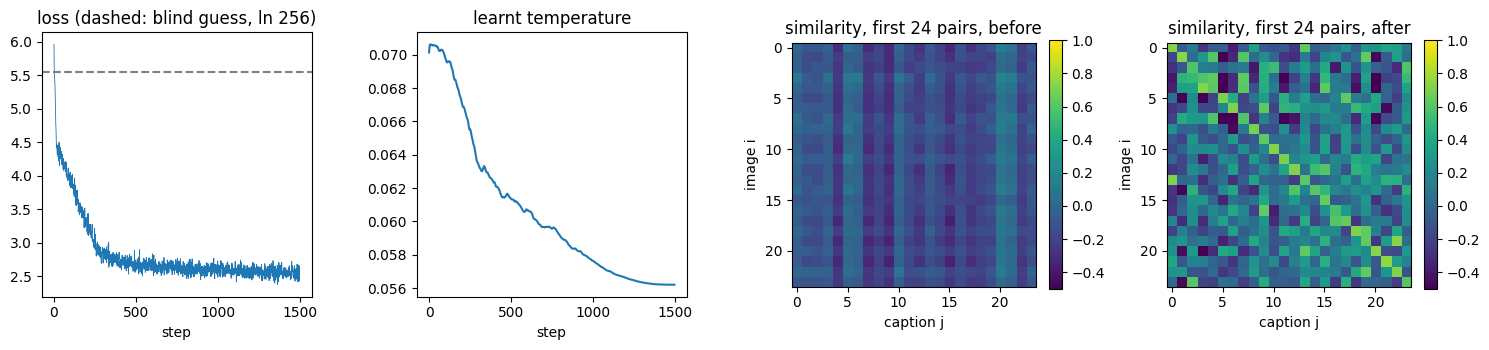

In [9]:
T_LEARNT = temps[-1]
loss1, sim1 = info_nce(image_tower(batch_x), text_tower(batch_ids), T_LEARNT)
sim1 = sim1.numpy()
print("loss on this batch after training:", round(float(loss1), 3))
print("mean similarity on the diagonal (true pairs):", round(float(np.diag(sim1).mean()), 3))
print("mean similarity, other captions that also fit:", round(float(sim1[fits & off].mean()), 3))
print("mean similarity, captions that do not fit    :", round(float(sim1[~fits].mean()), 3))
best = sim1.argmax(axis=1)
print(f"rows whose largest entry is the image's own caption: {100 * (best == np.arange(N)).mean():.1f}%")
print(f"rows whose largest entry is a caption that is true of the image: {100 * fits[np.arange(N), best].mean():.1f}%")
inv = {i: w for w, i in TOKEN.items()}
text_of = lambda row: " ".join(inv[i] for i in row if i > 0)
print("\nfirst 6 images and first 6 captions")
for k in range(6):
    print(f"  image {k}: {COLOURS[c_train[batch_idx[k]]]:>6} {y_train[batch_idx[k]]} | caption {k}: {text_of(batch_ids[k])}")
print(sim1[:6, :6])

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
ax[0].plot(losses, lw=0.6); ax[0].axhline(math.log(256), color="gray", ls="--")
ax[0].set_title("loss (dashed: blind guess, ln 256)"); ax[0].set_xlabel("step")
ax[1].plot(temps); ax[1].set_title("learnt temperature"); ax[1].set_xlabel("step")
for a, s, name in [(ax[2], sim0, "before"), (ax[3], sim1, "after")]:
    im = a.imshow(s[:24, :24], cmap="viridis", vmin=-0.5, vmax=1.0); a.set_title(f"similarity, first 24 pairs, {name}")
    a.set_xlabel("caption j"); a.set_ylabel("image i"); plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

### Why we see this

The table now has structure, and the structure is meaning. A caption that is true of an image scores high
whether or not it is that image's own caption. A caption that is false scores low. The model cannot tell "its
own" caption from another true one, and nothing in the pixels could tell it: a red three does not know
whether it was described as "a red 3" or "the digit three in red".

That is why the loss stops near 2.6 and not near zero. Asked to choose among several captions that are all
true, the best possible model can only share its probability among them. The loss counts every share that
went to a true caption other than the "official" one as an error. A model that shared evenly among an
image's own caption and 16.5 other true ones would pay about `ln 17.5 = 2.86` on the rows, which is the
neighbourhood the loss settles in. The second percentage printed above is the honest measure of what was
learnt.

The temperature moved **down** from 0.07: the model asked for a sharper softmax as its similarities became
trustworthy.

---
## Step 10 - Zero-shot classification: a sentence as a classifier

The model has no classifier head. Nothing in it has ten outputs. To classify digits anyway:

1. write one caption per class: "a photo of the digit zero", ..., "a photo of the digit nine";
2. embed the ten captions once, with the text tower: a `10 × 64` matrix;
3. embed the image and take the caption with the largest dot product.

Look at step 2 again. A `10 × 64` matrix that is multiplied by a feature vector, followed by an argmax, is a
`Dense(10)` layer without a bias. **The text tower has written the weights of a classifier from ten
sentences.** "Zero-shot" means no labelled example of the task was used to make that classifier. It does not
mean the model never saw a digit: it saw 50,000 of them, with captions.

We test on the 10,000 MNIST test images, which were never used in training, in all six colours.

**Predict:** the best a small CNN trained with labels reaches on MNIST is about 99%. Where will ten sentences
land: 50%, 90% or 99%?

In [10]:
def embed_text(txt, sentences):
    z = txt.predict(np.array([tokenize(s) for s in sentences], dtype="int32"), verbose=0)
    return z / np.linalg.norm(z, axis=1, keepdims=True)

def embed_images(img, x):
    z = img.predict(x, batch_size=1000, verbose=0)
    return z / np.linalg.norm(z, axis=1, keepdims=True)

def class_vectors(txt, templates, classes):
    """One unit vector per class: embed the class in every template, average, rescale to length 1."""
    rows = []
    for cl in classes:
        z = embed_text(txt, [t.format(**cl) for t in templates]).mean(axis=0)
        rows.append(z / np.linalg.norm(z))
    return np.array(rows)

def accuracy(z_img, w, labels, mask=None):
    ok = (z_img @ w.T).argmax(axis=1) == labels
    return 100 * float(ok.mean() if mask is None else ok[mask].mean())

z_test = embed_images(image_tower, X_test)                                    # (10000, 64), unit length
DIGITS_AS_WORDS = [{"d": w} for w in WORDS]
DIGITS_AS_NUMERALS = [{"d": str(d)} for d in range(10)]
w_digit = class_vectors(text_tower, ["a photo of the digit {d}"], DIGITS_AS_WORDS)
print("classifier made of sentences:", w_digit.shape, "| image vectors:", z_test.shape)
pred = (z_test @ w_digit.T).argmax(axis=1)
print(f"zero-shot digit accuracy, 10 classes, 10,000 test images: {accuracy(z_test, w_digit, y_test):.2f}% (chance 10%)")
print("accuracy by digit:", " ".join(f"{d}:{100 * (pred == y_test)[y_test == d].mean():.0f}" for d in range(10)))
w_colour = class_vectors(text_tower, ["something {c}"], [{"c": c} for c in COLOURS])
print(f"zero-shot colour accuracy, 6 classes: {accuracy(z_test, w_colour, c_test):.2f}% (chance 16.7%)")

classifier made of sentences: (10, 64) | image vectors: (10000, 64)
zero-shot digit accuracy, 10 classes, 10,000 test images: 93.66% (chance 10%)
accuracy by digit: 0:98 1:98 2:81 3:98 4:96 5:96 6:97 7:94 8:84 9:95


zero-shot colour accuracy, 6 classes: 100.00% (chance 16.7%)


### Why we see this

Ten sentences make a working digit classifier, and six make a colour classifier, from one model that was
never given a class index. Change the sentences and you have a different classifier, with no retraining.

It is also several points short of a supervised CNN on the same images, and that is the usual price. The
model was trained to match captions, many of which did not mention the digit at all. Colour is nearly
perfect because colour is easy to see and was named in 80% of captions.

---
## Step 11 - Prompt templates, and averaging them

The classifier's weights are made of words, so the wording matters. Three groups of prompts:

* the **bare class name**: "three". No training caption was ever a bare digit;
* the four **trained wordings** of digit-only captions;
* four **wordings the model never saw**, built from known words in new arrangements.

Then the trick CLIP's authors used (they averaged 80 templates for ImageNet): embed each class in several
templates and **average the vectors**. The hope is that the quirks of single wordings cancel.

**Predict:** will the bare name do as well as a full template? Will an average of prompts beat its own best
member?

In [11]:
UNSEEN = ["{d} written in ink", "ink {d}", "{d} a", "the {d} photo"]
print(f"{'prompt':<32}{'digit as word':>15}{'digit as numeral':>18}")
rows = [("{d}", ["{d}"])] + [(t, [t]) for t in DIGIT_ONLY] + [(t, [t]) for t in UNSEEN]
single = {}
for name, templates in rows:
    a = accuracy(z_test, class_vectors(text_tower, templates, DIGITS_AS_WORDS), y_test)
    b = accuracy(z_test, class_vectors(text_tower, templates, DIGITS_AS_NUMERALS), y_test)
    single[name] = a
    print(f"{name:<32}{a:>14.2f}%{b:>17.2f}%")
print()
for name, templates in [("average of the 4 trained", DIGIT_ONLY), ("average of the 4 unseen", UNSEEN),
                        ("average of bare + 4 unseen", ["{d}"] + UNSEEN), ("average of all 9", ["{d}"] + DIGIT_ONLY + UNSEEN)]:
    a = accuracy(z_test, class_vectors(text_tower, templates, DIGITS_AS_WORDS), y_test)
    members = [single[t] for t in templates]
    print(f"{name:<32}{a:>14.2f}%   members: mean {np.mean(members):.2f}%, best {max(members):.2f}%, worst {min(members):.2f}%")

prompt                            digit as word  digit as numeral


{d}                                      92.42%            92.35%


a photo of the digit {d}                 93.66%            93.64%


a {d}                                    93.64%            93.70%


the number {d}                           93.64%            93.65%


a handwritten {d}                        93.67%            93.71%


... (4 outputs left out)

average of the 4 trained                 93.68%   members: mean 93.65%, best 93.67%, worst 93.64%


average of the 4 unseen                  93.35%   members: mean 93.14%, best 93.50%, worst 92.39%


average of bare + 4 unseen               93.19%   members: mean 93.00%, best 93.50%, worst 92.39%


average of all 9                         93.58%   members: mean 93.29%, best 93.67%, worst 92.39%


### Why we see this

Read the printed table, not your expectation of it. Three things usually show.

* **The bare name loses about a point.** A lone word is a kind of text the tower never met. Its mean over
  the words is the word itself, with none of the company it was trained in. Wrapping the name in any familiar
  template brings the point back. This is the same effect, in miniature, as CLIP's "a photo of a {label}".
* **The trained wordings are nearly identical to each other.** With a 39-word vocabulary and thousands of
  repetitions, every trained template has been learnt equally well. There is little quirk to average away.
* **Averaging helps where the members are shaky.** An average of off-distribution prompts is usually at
  least as good as the mean of its members and close to its best member, without your having to know which
  one is best. It is cheap insurance, not magic. When the members are already good, it adds nothing.

In a real model the templates differ far more from each other, and the gain from averaging was large enough
for CLIP's authors to use it everywhere. The lab shows the mechanism and an honest small effect.

---
## Step 12 - A similarity is not a probability

Take one test image. Print its cosine similarity to the ten class sentences, and then the softmax of those
similarities at three temperatures: 1 (the raw scores), the learnt temperature, and 0.01.

Then make one deliberate mistake: skip the normalisation of the class vectors.

**Predict:** the right class will have the highest similarity. Will that similarity be near 1.0? What
"confidence" does the softmax give at each temperature?

In [12]:
def softmax(v):
    e = np.exp(v - v.max())
    return e / e.sum()

k = 0
s = z_test[k] @ w_digit.T
print(f"test image {k} is a {COLOURS[c_test[k]]} {y_test[k]}")
print("cosine similarity to the ten class sentences:", s)
for temp in [1.0, T_LEARNT, 0.01]:
    p = softmax(s / temp)
    print(f"softmax at temperature {temp:<6.4g}: top class {p.argmax()} with 'probability' {p.max():.3f}")
right = (z_test @ w_digit.T)[np.arange(len(y_test)), y_test]
print(f"\nover all test images: similarity to the correct class sentence, mean {right.mean():.3f}, "
      f"5th percentile {np.percentile(right, 5):.3f}, 95th percentile {np.percentile(right, 95):.3f}")

raw = text_tower.predict(np.array([tokenize(f"a photo of the digit {w}") for w in WORDS], dtype="int32"), verbose=0)
print("\nlengths of the ten class vectors before normalising:", np.linalg.norm(raw, axis=1))
print(f"accuracy with class vectors normalised: {accuracy(z_test, w_digit, y_test):.2f}% | "
      f"not normalised: {accuracy(z_test, raw, y_test):.2f}%")

test image 0 is a yellow 7
cosine similarity to the ten class sentences: [ 0.17  0.32  0.31  0.17  0.16  0.13 -0.12  0.62  0.03  0.23]
softmax at temperature 1     : top class 7 with 'probability' 0.149
softmax at temperature 0.05621: top class 7 with 'probability' 0.990
softmax at temperature 0.01  : top class 7 with 'probability' 1.000

over all test images: similarity to the correct class sentence, mean 0.600, 5th percentile 0.480, 95th percentile 0.653

lengths of the ten class vectors before normalising: [21.83 20.72 20.02 22.12 20.46 24.5  18.37 21.57 20.98 22.02]
accuracy with class vectors normalised: 93.66% | not normalised: 92.43%


### Why we see this

The similarity to the correct sentence is well short of 1, and it has to be: the caption "a photo of the
digit seven" says nothing about colour, so it cannot sit exactly where a red seven sits. A matched pair in a
contrastive model has a **moderate** cosine similarity, not a high one. Anyone who sets a threshold such as
"similarity above 0.9 means a match" will match nothing.

The "probability" you get depends entirely on the temperature you divide by. The same ten scores give a
timid answer at temperature 1 and near-certainty at 0.01. None of the three is a calibrated probability
(Chapter 63). And the softmax only compares the candidates you supplied: if the true answer is not among
your ten sentences, one of them still wins.

Skipping the normalisation changes the answer whenever the class vectors have different lengths: longer
vectors win more dot products for reasons that have nothing to do with the image.

---
## Step 13 - Search: text to image

Zero-shot classification holds the image fixed and compares sentences. Turn the table on its side: hold a
**sentence** fixed and compare images. The 10,000 test images are embedded once (we already have `z_test`).
A query costs one pass through the text tower and one matrix product. This is the bi-encoder of Chapter 42
with pictures as the documents.

We score each query by **precision at 10**: of the ten images returned, how many match the query.

**Predict:** for "a blue seven", how many of the top ten will be blue sevens? And for the vaguer "something
green"?

'a blue seven'                           precision at 10: 1.0   returned: blue-7 blue-7 blue-7 blue-7 blue-7 ...
'the number 4 written in yellow ink'     precision at 10: 1.0   returned: yellow-4 yellow-4 yellow-4 yellow-4 yellow-4 ...
'pink handwritten nine'                  precision at 10: 1.0   returned: pink-9 pink-9 pink-9 pink-9 pink-9 ...
'something green'                        precision at 10: 1.0   returned: green-9 green-2 green-5 green-5 green-5 ...


'a handwritten 5'                        precision at 10: 1.0   returned: blue-5 green-5 green-5 red-5 yellow-5 ...


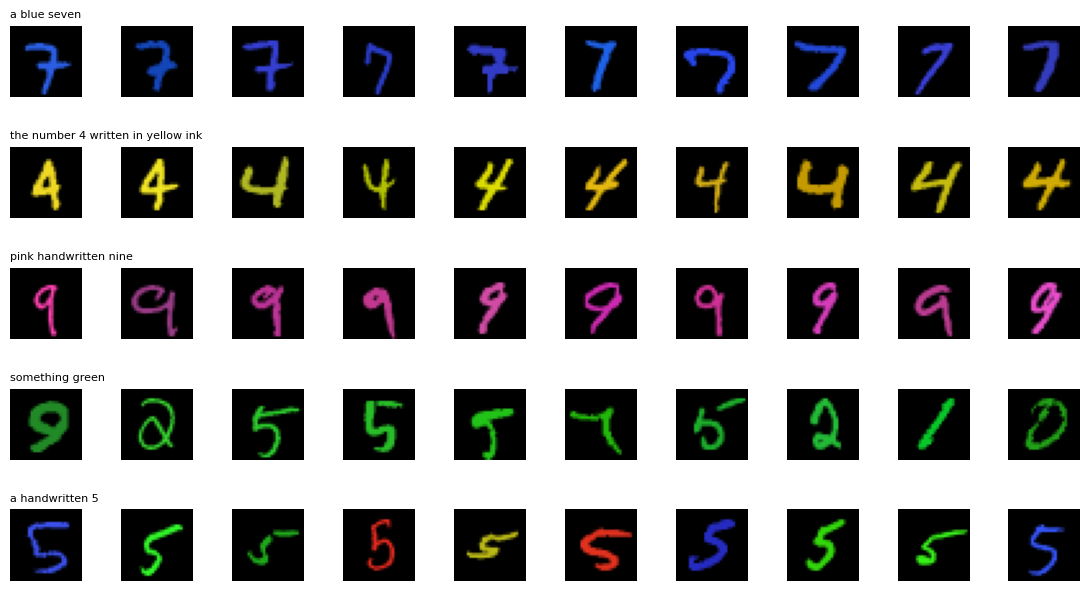


all 60 queries 'a <colour> <digit>': mean precision at 10 = 99.3% (50 seen combinations 99.8%, 10 held-out combinations 97.0%)


In [13]:
def search(sentence, k=10):
    q = embed_text(text_tower, [sentence])[0]
    return np.argsort(-(z_test @ q))[:k]

queries = [("a blue seven", 7, 2), ("the number 4 written in yellow ink", 4, 3), ("pink handwritten nine", 9, 4),
           ("something green", None, 1), ("a handwritten 5", 5, None)]
fig, ax = plt.subplots(len(queries), 10, figsize=(11, 1.25 * len(queries)))
for r, (sentence, d, c) in enumerate(queries):
    top = search(sentence)
    ok = np.ones(10, dtype=bool)
    if d is not None: ok &= y_test[top] == d
    if c is not None: ok &= c_test[top] == c
    print(f"{sentence!r:40} precision at 10: {ok.mean():.1f}   returned: "
          + " ".join(f"{COLOURS[c_test[j]]}-{y_test[j]}" for j in top[:5]) + " ...")
    for j, a in zip(top, ax[r]):
        a.imshow(X_test[j]); a.axis("off")
    ax[r, 0].set_title(sentence, fontsize=8, loc="left")
plt.tight_layout(); plt.show()

label60 = y_test * 6 + c_test                                                  # one number per combination
p10 = []
for d in range(10):
    for c in range(6):
        top = search(f"a {COLOURS[c]} {WORDS[d]}")
        p10.append((label60[top] == d * 6 + c).mean())
p10 = np.array(p10)
held_combo = np.array([c == d % 6 for d in range(10) for c in range(6)])
print(f"\nall 60 queries 'a <colour> <digit>': mean precision at 10 = {100 * p10.mean():.1f}% "
      f"(50 seen combinations {100 * p10[~held_combo].mean():.1f}%, 10 held-out combinations {100 * p10[held_combo].mean():.1f}%)")

### Why we see this

The top of a ranked list is the easy end: among 10,000 images there are about 170 of each combination, and
the search only has to put ten clear examples first. That is why precision at 10 can be perfect while
classification of every image (Step 10) is not. A search engine is judged at the top of its list, a
classifier on every item, including the awkward ones.

Notice that the queries were in different wordings, with words and numerals, and that the query for a
held-out combination works at the top of the list too. Step 15 looks at those combinations more severely.

---
## Step 14 - What the text tower learnt: synonyms it was never told, and word order it never needed

Two tests on the text tower alone.

**Synonyms.** Compare "a three" with "a 3", and "a three" with the other numerals.

**Word order.** Compare a caption with the same words scrambled.

**Predict:** your answer from Step 3: how similar are "a three" and "a 3"? And how similar is "a photo of a
red three" to "three red a of photo a"?

In [14]:
zw = embed_text(text_tower, [f"a {w}" for w in WORDS])
zn = embed_text(text_tower, [f"a {d}" for d in range(10)])
s = zw @ zn.T
print("similarity of 'a <word>' with 'a <numeral>' for the same digit:", np.diag(s))
print("mean similarity for different digits:", round(float(s[~np.eye(10, dtype=bool)].mean()), 3))

pairs = [("a photo of a red three", "three red a of photo a"),
         ("a photo of a red three", "a photo of a three red"),
         ("the number 4 written in yellow ink", "ink yellow in written 4 number the"),
         ("a red three", "a blue three"), ("a red three", "a red five")]
for a, b in pairs:
    za, zb = embed_text(text_tower, [a, b])
    print(f"{a!r:38} vs {b!r:38} similarity {float(za @ zb):.3f}")

similarity of 'a <word>' with 'a <numeral>' for the same digit: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
mean similarity for different digits: 0.478
'a photo of a red three'               vs 'three red a of photo a'               similarity 0.973


'a photo of a red three'               vs 'a photo of a three red'               similarity 0.992
'the number 4 written in yellow ink'   vs 'ink yellow in written 4 number the'   similarity 0.983


'a red three'                          vs 'a blue three'                         similarity 0.535
'a red three'                          vs 'a red five'                           similarity 0.536


### Why we see this

**"three" and "3" have become the same point**, although no caption ever contained both and nothing said
they were related. They were joined through the pictures: both words were pulled towards the same images, so
they were pulled towards each other. This is how a contrastive model learns that "sofa" and "couch", or a
word in two languages, mean one thing. The image is the dictionary.

**Scrambling the words changes almost nothing.** The tower has attention and a position table, so it could
have learnt to read order. It did not, because no caption in this lab needed it: there is no pair of
training captions that have the same words in a different order and mean different things. A model learns
what its loss rewards. A scrambled caption and the original land together, while changing one content word
(red to blue, three to five) moves the vector a long way. The tower is a **bag of concepts**. The chapter
explains why the full-size CLIP has a milder form of the same habit, for the same reason.

---
## Step 15 - New, kind one: a combination of known words

Ten combinations were never shown: a red zero, a green one, a blue two, and so on. The model has seen red
things, and it has seen zeros, in other pairings. Can it recognise a red zero from the caption "a red zero"?

This is the hard test: **60-way** classification, one caption per combination, so the unseen caption has to
beat 59 others, 50 of which the model was trained on. We split the test images into those from seen
combinations and those from held-out ones.

**Predict:** will accuracy on the held-out combinations be near 0%, about half, or as good as on the seen
ones? When it fails, which half does it get wrong: the colour or the digit?

In [15]:
COMBOS = [{"d": WORDS[d], "c": COLOURS[c]} for d in range(10) for c in range(6)]
w60 = class_vectors(text_tower, ["a {c} {d}"], COMBOS)
pred60 = (z_test @ w60.T).argmax(axis=1)
pd_, pc_ = pred60 // 6, pred60 % 6
print(f"{'test images from':<28}{'count':>7}{'both right':>12}{'digit right':>13}{'colour right':>14}")
for name, m in [("50 seen combinations", ~held_test), ("10 held-out combinations", held_test)]:
    print(f"{name:<28}{m.sum():>7,}{100 * (pred60 == label60)[m].mean():>11.2f}%"
          f"{100 * (pd_ == y_test)[m].mean():>12.2f}%{100 * (pc_ == c_test)[m].mean():>13.2f}%")
wrong = held_test & (pred60 != label60)
to_seen = ~np.array([c == d % 6 for d, c in zip(pd_[wrong], pc_[wrong])])
print(f"\nheld-out images that were misread: {wrong.sum()}; of those, given a caption from a SEEN combination: "
      f"{100 * to_seen.mean():.1f}%")
# the same images, asked only about the digit
print(f"digit-only question ('a photo of the digit ...'), 10 classes: seen {accuracy(z_test, w_digit, y_test, ~held_test):.2f}% "
      f"| held-out {accuracy(z_test, w_digit, y_test, held_test):.2f}%")
by_combo = [100 * (pred60 == label60)[held_test & (y_test == d)].mean() for d in range(10)]
print("held-out accuracy by combination:", " ".join(f"{COLOURS[d % 6]}-{d}:{by_combo[d]:.0f}" for d in range(10)))
worst = int(np.argmin(by_combo))
m = held_test & (y_test == worst)
names, counts = np.unique(pred60[m], return_counts=True)
order = np.argsort(-counts)[:4]
print(f"the {m.sum()} images of the worst one, '{COLOURS[worst % 6]} {WORDS[worst]}', are called:",
      ", ".join(f"'{COLOURS[n % 6]} {WORDS[n // 6]}' {c}" for n, c in zip(names[order], counts[order])))

test images from              count  both right  digit right  colour right
50 seen combinations          8,357      97.70%       97.70%       100.00%
10 held-out combinations      1,643      79.18%       79.18%       100.00%

held-out images that were misread: 342; of those, given a caption from a SEEN combination: 98.2%
digit-only question ('a photo of the digit ...'), 10 classes: seen 97.75% | held-out 72.85%
held-out accuracy by combination: red-0:96 green-1:96 blue-2:3 yellow-3:97 pink-4:91 white-5:93 red-6:97 green-7:90 blue-8:30 yellow-9:96
the 181 images of the worst one, 'blue two', are called: 'blue three' 93, 'blue seven' 25, 'blue five' 22, 'blue six' 18


### Why we see this

Read the line of accuracies by combination before the average. For most held-out combinations the model is
nearly as good as on combinations it trained on. It has learnt the colour and the digit as separate ideas
that can be put together, and that is the route by which a contrastive model handles things nobody labelled
for it: **new combinations of familiar parts**.

Then there are the exceptions: one or two combinations on which it fails badly, and they drag the average
down. The pattern of errors says what kind of failure this is. The colour is always right. The digit is
swapped for another digit in the same colour, and nearly every wrong answer is a caption from a combination
the model **was** trained on. Training taught it that this pairing never happens, and it believed it.

The digit-only line shows where the fault lies. Even when the caption does not mention colour at all, the
held-out images are misread. So the text tower is not the problem: it composes words happily. The **image
tower** has not fully separated shape from colour. It learnt to see a two in the colours it met a two in,
and that skill carried over to most new colours and not to all.

Which combinations fail varies with the seed and the colours. A plausible reading, which this lab does not
test, is that a colour unlike the others shares fewer of the detectors learnt on them. Trial 5 and your own
changes to `RGB` let you test it. The lesson that does not depend on the seed: **composition is a habit the
data encouraged, not a guarantee**, and an average hides the places where it breaks.

---
## Step 16 - New, kind two: a new kind of object

Now something the model has never seen at all: clothes. Tint the Fashion-MNIST test images with the same six
colours and ask the colour question with the same sentences.

**Predict:** the model has never seen a shoe. Can it say which colour a shoe is? Can it say which digit a
shoe is?

In [16]:
(_, _), (xf, yf) = keras.datasets.fashion_mnist.load_data()
xf = (xf / 255.0).astype("float32")
cf = rng.integers(0, 6, len(xf))
z_fashion = embed_images(image_tower, colourise(xf, cf, rng))
print(f"zero-shot colour accuracy on 10,000 tinted Fashion-MNIST items: {accuracy(z_fashion, w_colour, cf):.2f}% (chance 16.7%)")
votes = np.bincount((z_fashion @ w_digit.T).argmax(axis=1), minlength=10)
print("asked 'which digit?', the clothes are called:", " ".join(f"{d}:{v}" for d, v in enumerate(votes)))
right_f = (z_fashion @ w_digit.T).max(axis=1)
print(f"similarity to the winning digit sentence: clothes {right_f.mean():.3f} | real digits {(z_test @ w_digit.T).max(axis=1).mean():.3f}")

zero-shot colour accuracy on 10,000 tinted Fashion-MNIST items: 100.00% (chance 16.7%)
asked 'which digit?', the clothes are called: 0:814 1:32 2:1686 3:98 4:2783 5:124 6:509 7:6 8:3606 9:342
similarity to the winning digit sentence: clothes 0.523 | real digits 0.608


### Why we see this

Colour transfers to objects the model never saw, because colour is a property of pixels that looks the same
on a boot as on a seven, and the captions named it. That is zero-shot transfer in the proper sense: a new
dataset, no examples of it, a correct answer.

The digit question has no right answer for a shoe, and the model answers anyway. Zero-shot classification
picks the nearest of the sentences you offer. It has no way of saying "none of these". Compare the two
similarity figures: is the winning score lower for clothes, and would you trust a threshold on it?

---
## Step 17 - New, kind three: a word the model never read

Last experiment. Train a second model from scratch on digits **0 to 7 only**. It never sees a picture of an 8
or a 9, and the words "eight", "nine", "8" and "9" never appear in a caption. Those four words are in the
vocabulary, so they have rows in the word table, but no gradient ever reaches those rows: they stay at their
random starting values.

Then ask it to classify all ten digits by name.

**Predict:** what accuracy on 8s and 9s? And if you offer only two captions, "eight" and "nine", to images
that are all 8s or 9s, how often is it right: about 0%, about 50%, or about 100%? (A trap: think about what
decides it.)

In [17]:
t = time.time()
image_b, text_b, losses_b, temps_b = train_clip(1000, y_train < 8)
print(f"second model: 1,000 steps on digits 0 to 7 took {time.time() - t:.0f}s; final loss {np.mean(losses_b[-100:]):.3f}")
z_b = embed_images(image_b, X_test)
w_b = class_vectors(text_b, ["a photo of the digit {d}"], DIGITS_AS_WORDS)
pred_b = (z_b @ w_b.T).argmax(axis=1)
print("accuracy by digit:", " ".join(f"{d}:{100 * (pred_b == y_test)[y_test == d].mean():.1f}" for d in range(10)))
print(f"digits 0 to 7: {100 * (pred_b == y_test)[y_test < 8].mean():.2f}% | digits 8 and 9: {100 * (pred_b == y_test)[y_test >= 8].mean():.2f}%")
for d in (8, 9):
    print(f"images of {d} are called:", " ".join(f"{k}:{v}" for k, v in enumerate(np.bincount(pred_b[y_test == d], minlength=10))))
m = y_test >= 8
two_way = (z_b[m] @ w_b[8:].T).argmax(axis=1) + 8
print(f"two captions only, 'eight' against 'nine', on the {m.sum():,} images of 8s and 9s: {100 * (two_way == y_test[m]).mean():.2f}% (a coin: 50%)")
swapped = (z_b[m] @ w_b[[9, 8]].T).argmax(axis=1) + 8
print(f"the same with the two names swapped: {100 * (swapped == y_test[m]).mean():.2f}%")

# the rows of 'eight', 'nine', '8', '9' in the word table were never trained. Redraw them at random 20 times.
table = text_b.layers[1]
assert isinstance(table, layers.Embedding)
start = table.get_weights()[0]
rows_new = [TOKEN[w] for w in ("eight", "nine", "8", "9")]
dice, scores = np.random.default_rng(1), []
for _ in range(20):
    redrawn = start.copy()
    redrawn[rows_new] = dice.uniform(-0.05, 0.05, (4, D))                      # Keras's starting range for a word table
    table.set_weights([redrawn])
    w2 = class_vectors(text_b, ["a photo of the digit {d}"], DIGITS_AS_WORDS[8:])
    scores.append(100 * ((z_b[m] @ w2.T).argmax(axis=1) + 8 == y_test[m]).mean())
table.set_weights([start])
print("'eight' against 'nine' with the untrained rows redrawn 20 times:", " ".join(f"{v:.0f}" for v in sorted(scores)))
print(f"mean {np.mean(scores):.1f}% | lowest {min(scores):.1f}% | highest {max(scores):.1f}%")
print(f"\nwhole notebook: {time.time() - t_start:.0f}s")

second model: 1,000 steps on digits 0 to 7 took 31s; final loss 2.646


accuracy by digit: 0:98.8 1:98.4 2:96.1 3:96.3 4:97.6 5:96.3 6:97.0 7:97.6 8:18.5 9:1.3
digits 0 to 7: 97.28% | digits 8 and 9: 9.73%
images of 8 are called: 0:11 1:6 2:169 3:99 4:24 5:257 6:18 7:26 8:180 9:184
images of 9 are called: 0:10 1:5 2:5 3:8 4:176 5:31 6:0 7:574 8:187 9:13
two captions only, 'eight' against 'nine', on the 1,983 images of 8s and 9s: 21.73% (a coin: 50%)
the same with the two names swapped: 78.27%


'eight' against 'nine' with the untrained rows redrawn 20 times: 10 13 13 21 25 35 36 37 38 41 45 47 58 61 62 67 70 72 81 85
mean 45.7% | lowest 9.9% | highest 84.7%

whole notebook: 134s


### Why we see this

On the 8s and 9s the ten-way accuracy is far below the other digits, and whatever it shows is an accident.
The two-caption test makes that plain. Its score is not knowledge: swap the two names and you get exactly
the mirror image. The model has a fixed, meaningless preference, set by where two **random** rows of the
word table happened to point. Redraw those rows and the score lands somewhere else, and over many redraws
it averages out near a coin toss. **To this model "eight" and "nine" are noise.** A single run that happened
to score 80% would have looked like zero-shot success. Only the repeats show that it is dice.

Look at what the 8s and 9s are called instead: mostly the trained digits they resemble. The image tower does
its best with a shape it never saw, and the nearest familiar caption wins.

Put the last three steps side by side. They are three different meanings of "the model never saw this":

| New thing | Example | Route to the right answer | Result |
|---|---|---|---|
| a new **combination** of known words | "a red zero" | both words were learnt separately | works for most, fails badly for a few (Step 15) |
| a new **kind of object**, known word | a red shoe | the word names a property the pixels share | works for that property (Step 16) |
| a new **word** | "eight" | none: the word was never tied to any picture | dice (Step 17) |

CLIP's zero-shot ability is of the first two kinds, at enormous scale. Its training captions had already used
nearly every word you are likely to type. When a class name is rare or absent on the web, CLIP is in the
position of this second model.

---
## Trials: change one thing at a time

Each trial changes one number or one line. Write your prediction first.

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Fix the temperature: in `train_clip` remove `[log_scale]` from `weights`, and try `LOG_SCALE_START = math.log(1 / 0.5)`, then `math.log(1 / 0.01)` | Which direction hurts more, too gentle or too sharp? What happens to the first logged loss? | |
| 2 | `train_clip(..., batch_size=32)` with `TRAIN_STEPS = 12000` so the pairs seen stay equal | Fewer wrong captions per question, but also fewer false negatives. Better or worse zero-shot accuracy? | |
| 3 | In `caption`, make every caption full (`templates = FULL`) | What happens to the loss floor? To digit-only zero-shot accuracy in Step 10? | |
| 4 | In `caption`, always use the word, never the numeral; then classify with numerals in Step 11 | What accuracy do the numeral prompts get, and why? | |
| 5 | Hold out 30 combinations instead of 10: `held_train = (c_train + y_train) % 2 == 0` (and the same for `held_test`) | Does the accuracy on unseen combinations rise or fall when the model sees fewer pairings? | |
| 6 | In `info_nce`, comment out the two `l2_normalize` lines (and embed without normalising) | What does the temperature do now? What happens to the lengths of the vectors? | |
| 7 | Replace `MaskedMean` by the vector of the first token only | Can the text tower still work? Does word order start to matter in Step 14? | |
| 8 | Use `keras.datasets.fashion_mnist` for training, with captions naming the garment | Which garments will zero-shot classification confuse? | |

## Exercises

1. **Remove the false negatives.** In `train_clip`, build the `fits` table of Step 7 for each batch and mask
   every off-diagonal cell where the caption also fits the image (set its logit to a large negative number).
   How far does the loss fall? Does zero-shot accuracy change? What would you need in order to do this on web
   data?
2. **Sigmoid instead of softmax.** Replace the two cross-entropies by one binary cross-entropy over all
   `N × N` cells (label 1 on the diagonal, 0 elsewhere) with a learnt temperature and a learnt bias. This is
   the idea of SigLIP (2023). Compare zero-shot accuracy at batch sizes 32 and 256.
3. **A few labelled examples.** Take the second model of Step 17 and 20 captioned images each of 8 and 9.
   Fine-tune for 50 steps (Chapter 39). How many examples does it take before "eight" beats a coin?
4. **Teach it word order.** Add two-digit images (two digits side by side) with captions such as "a red
   three left of a blue seven". Check Step 14 again. What is the smallest change to the data that makes the
   scrambled caption land somewhere else?
5. **Image-to-image search.** Use `z_test` alone: for a query image, return its ten nearest images. Which
   matters more to the image tower, colour or digit? Why does the answer follow from the captions?
6. **A linear probe on the image tower.** Freeze the image tower, train `Dense(10)` on its 128 features
   before the projection (Chapter 48, Step 10), and compare with the zero-shot accuracy of Step 10. What
   does the gap measure?

## Cheat sheet

| Idea | One line |
|---|---|
| Two towers | an image encoder and a text encoder that share only the width of their output |
| The loss | cross-entropy along the rows and down the columns of the N × N similarity table; the diagonal is the answer |
| Learnt temperature | stored as ln(1 / temperature), starts at ln(1 / 0.07), capped at ln 100 |
| Zero-shot classification | embed one sentence per class; the nearest sentence wins; no labelled examples of the task |
| The classifier is made of words | the matrix of class vectors is a `Dense` layer written by the text tower |
| Prompt template | wrap the class name in the kind of sentence the model was trained on |
| Prompt ensemble | embed several templates per class, average, rescale to length 1 |
| Retrieval | embed the images once; a query is one text embedding and one matrix product |
| False negatives | other captions in the batch that are also true; they set a floor under the loss |
| Scores | cosine similarities of true pairs are moderate; a softmax over them is not a calibrated probability |
| What transfers | new combinations of known words, known words on new objects; never a word the model has not read |

```python
def zero_shot(image_tower, text_tower, images, class_names, templates):
    w = []
    for name in class_names:                                   # one vector per class
        z = text_tower.predict(np.array([tokenize(t.format(d=name)) for t in templates]), verbose=0)
        z = (z / np.linalg.norm(z, axis=1, keepdims=True)).mean(axis=0)
        w.append(z / np.linalg.norm(z))
    z_img = image_tower.predict(images, verbose=0)
    z_img = z_img / np.linalg.norm(z_img, axis=1, keepdims=True)
    return (z_img @ np.array(w).T).argmax(axis=1)              # index of the nearest sentence
```